In [4]:
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, Subset
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np, random, time, json
import matplotlib.pyplot as plt

# Seed
def set_seed(s=42):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# Dataset — otomatis download dari Oxford
ds = ConcatDataset([
    datasets.OxfordIIITPet('./data', split='trainval', download=True),
    datasets.OxfordIIITPet('./data', split='test',     download=True),
])

# Ambil 10 kelas pertama (5 kucing + 5 anjing)
indices = [i for i in range(len(ds)) if ds[i][1] < 10]
labels  = [ds[i][1] for i in indices]
tr_idx, tmp_idx, tr_y, tmp_y = train_test_split(
    indices, labels, test_size=0.3, stratify=labels, random_state=42)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.5,
                                  stratify=tmp_y, random_state=42)
print(f"Train={len(tr_idx)} Val={len(va_idx)} Test={len(te_idx)}")

Device: cuda


100%|██████████| 792M/792M [00:30<00:00, 25.9MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.6MB/s]


Train=1386 Val=297 Test=298


In [5]:
mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class Wrap(torch.utils.data.Dataset):
    def __init__(self, base, idx, tf): self.base,self.idx,self.tf = base,idx,tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        x, y = self.base[self.idx[i]]
        return self.tf(x), y

def loaders(aug=False, bs=32):
    tf = train_tf if aug else eval_tf
    tr = DataLoader(Wrap(ds, tr_idx, tf), bs, shuffle=True,  num_workers=2)
    va = DataLoader(Wrap(ds, va_idx, eval_tf), bs, shuffle=False, num_workers=2)
    te = DataLoader(Wrap(ds, te_idx, eval_tf), bs, shuffle=False, num_workers=2)
    return tr, va, te

In [6]:
def make_model(kind):
    if kind == 'B1':  # from scratch
        m = models.resnet18(weights=None)
    else:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        if kind == 'B3':  # fine-tune layer4
            for p in m.layer4.parameters(): p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m

def run(kind, aug=False, epochs=15, patience=3):
    tr, va, te = loaders(aug)
    m = make_model(kind).to(device)
    if kind == 'B1':
        opt = optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-2)
    elif kind == 'B2':
        opt = optim.AdamW(m.fc.parameters(), lr=1e-3, weight_decay=1e-2)
    else:
        opt = optim.AdamW([
            {'params': m.layer4.parameters(), 'lr': 1e-4},
            {'params': m.fc.parameters(),     'lr': 1e-3},
        ], weight_decay=1e-2)
    crit = nn.CrossEntropyLoss()
    hist = {'tr': [], 'va': []}
    best, wait, best_state = 1e9, 0, None
    t0 = time.time()
    for ep in range(epochs):
        m.train(); tl = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); l = crit(m(x), y); l.backward(); opt.step()
            tl += l.item()*x.size(0)
        tl /= len(tr.dataset)
        m.eval(); vl = 0; ps, ys = [], []
        with torch.no_grad():
            for x, y in va:
                x, y = x.to(device), y.to(device)
                o = m(x); vl += crit(o, y).item()*x.size(0)
                ps += o.argmax(1).cpu().tolist(); ys += y.cpu().tolist()
        vl /= len(va.dataset); acc = accuracy_score(ys, ps)
        hist['tr'].append(tl); hist['va'].append(vl)
        print(f"{kind} Ep{ep+1:02d} tr={tl:.3f} va={vl:.3f} acc={acc:.3f}")
        if vl < best: best, best_state, wait = vl, {k:v.clone() for k,v in m.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    m.load_state_dict(best_state)
    # Test
    m.eval(); ps, ys = [], []
    with torch.no_grad():
        for x, y in te:
            ps += m(x.to(device)).argmax(1).cpu().tolist(); ys += y.tolist()
    return m, hist, accuracy_score(ys, ps), f1_score(ys, ps, average='macro'), time.time()-t0

results = {}
for kind, aug in [('B1',False), ('B2',False), ('B3',False), ('B4',True)]:
    m, h, acc, f1, dur = run(kind, aug)
    results[kind] = {'acc':acc, 'f1':f1, 'dur':dur, 'hist':h}
    print(f"→ {kind}: acc={acc:.4f} f1={f1:.4f} ({dur:.1f}s)\n")

# Simpan log
with open('results.json','w') as f: json.dump(results, f, indent=2)

B1 Ep01 tr=2.265 va=2.454 acc=0.286
B1 Ep02 tr=1.927 va=2.255 acc=0.286
B1 Ep03 tr=1.765 va=2.172 acc=0.313
B1 Ep04 tr=1.663 va=1.982 acc=0.323
B1 Ep05 tr=1.566 va=1.874 acc=0.391
B1 Ep06 tr=1.482 va=2.051 acc=0.370
B1 Ep07 tr=1.405 va=1.842 acc=0.411
B1 Ep08 tr=1.322 va=2.349 acc=0.350
B1 Ep09 tr=1.196 va=1.815 acc=0.394
B1 Ep10 tr=1.189 va=1.780 acc=0.441
B1 Ep11 tr=1.001 va=1.727 acc=0.455
B1 Ep12 tr=0.974 va=2.186 acc=0.441
B1 Ep13 tr=0.855 va=1.992 acc=0.461
B1 Ep14 tr=0.724 va=1.780 acc=0.475
→ B1: acc=0.4597 f1=0.4443 (139.6s)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


B2 Ep01 tr=1.399 va=0.720 acc=0.855
B2 Ep02 tr=0.604 va=0.451 acc=0.906
B2 Ep03 tr=0.421 va=0.356 acc=0.916
B2 Ep04 tr=0.347 va=0.316 acc=0.919
B2 Ep05 tr=0.293 va=0.305 acc=0.926
B2 Ep06 tr=0.267 va=0.281 acc=0.912
B2 Ep07 tr=0.243 va=0.279 acc=0.919
B2 Ep08 tr=0.219 va=0.265 acc=0.923
B2 Ep09 tr=0.193 va=0.253 acc=0.916
B2 Ep10 tr=0.195 va=0.251 acc=0.909
B2 Ep11 tr=0.174 va=0.251 acc=0.912
B2 Ep12 tr=0.163 va=0.248 acc=0.912
B2 Ep13 tr=0.166 va=0.231 acc=0.919
B2 Ep14 tr=0.150 va=0.264 acc=0.906
B2 Ep15 tr=0.138 va=0.234 acc=0.929
→ B2: acc=0.9530 f1=0.9533 (136.8s)

B3 Ep01 tr=0.754 va=0.264 acc=0.906
B3 Ep02 tr=0.131 va=0.219 acc=0.939
B3 Ep03 tr=0.045 va=0.191 acc=0.936
B3 Ep04 tr=0.018 va=0.188 acc=0.946
B3 Ep05 tr=0.011 va=0.183 acc=0.946
B3 Ep06 tr=0.007 va=0.194 acc=0.939
B3 Ep07 tr=0.008 va=0.193 acc=0.943
B3 Ep08 tr=0.005 va=0.195 acc=0.929
→ B3: acc=0.9530 f1=0.9531 (78.2s)

B4 Ep01 tr=1.512 va=0.788 acc=0.822
B4 Ep02 tr=0.667 va=0.446 acc=0.906
B4 Ep03 tr=0.448 va=0.368 a

In [7]:
class RemapDataset(torch.utils.data.Dataset):
    """Dataset yang me-remap label asli ke label 0-9."""
    def __init__(self, base_dataset, indices, label_map, transform=None):
        self.base = base_dataset
        self.indices = indices
        self.label_map = label_map
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, y = self.base[self.indices[idx]]
        if self.transform:
            img = self.transform(img)
        return img, self.label_map[y]

# Normalisasi ImageNet
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

# Augmentasi untuk train
train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

# Deterministik untuk val/test
eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

def build_datasets(augment=False):
    train_tf = train_transforms_aug if augment else eval_transforms
    train_ds = RemapDataset(combined, train_idx, label_map, transform=train_tf)
    val_ds   = RemapDataset(combined, val_idx,   label_map, transform=eval_transforms)
    test_ds  = RemapDataset(combined, test_idx,  label_map, transform=eval_transforms)
    return train_ds, val_ds, test_ds

def get_dataloaders(augment=False, batch_size=32):
    train_ds, val_ds, test_ds = build_datasets(augment=augment)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=4, persistent_workers=True, pin_memory=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                              num_workers=4, persistent_workers=True, pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                              num_workers=4, persistent_workers=True, pin_memory=True)
    return train_loader, val_loader, test_loader

In [8]:
def get_model(condition):
    if condition == 'B1':  # from scratch
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 10)

    elif condition == 'B2':  # feature extraction
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, 10)

    elif condition in ['B3', 'B4']:  # fine-tune layer4
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        for p in model.layer4.parameters():
            p.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, 10)

    elif condition == 'B5':  # EfficientNet-B0
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        for p in model.features[-1].parameters():
            p.requires_grad = True
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, 10)

    return model

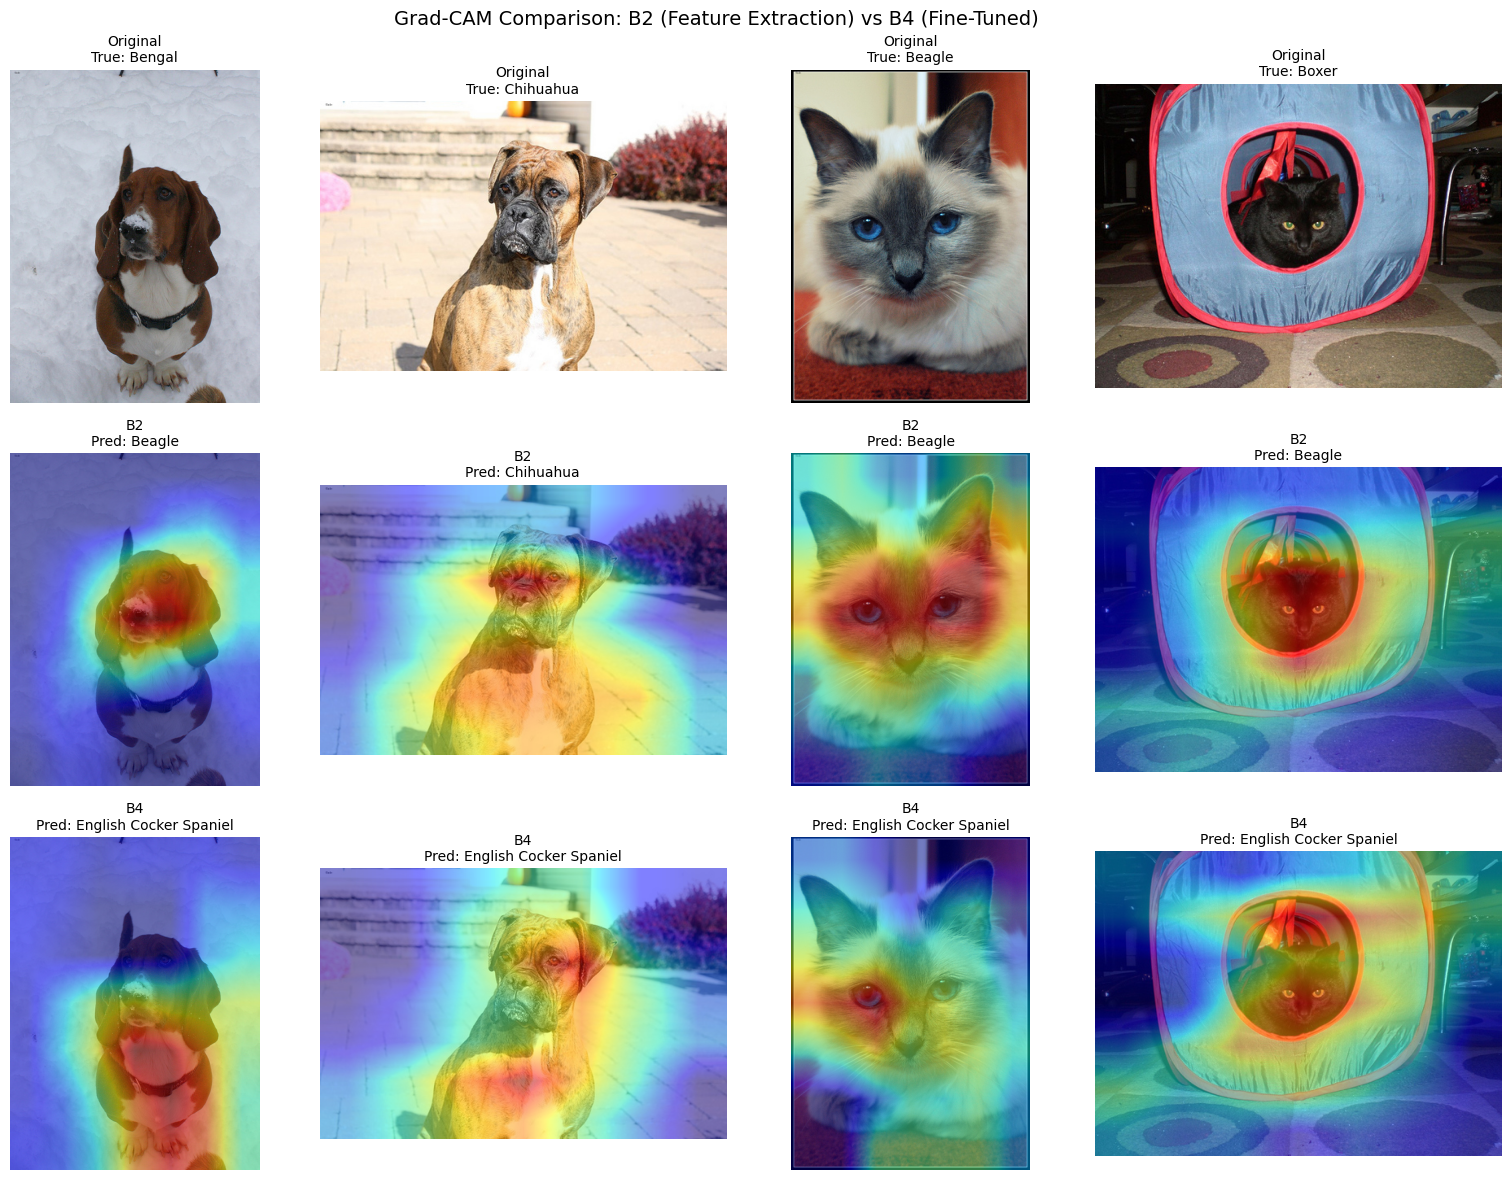

✅ Grad-CAM disimpan sebagai gradcam_comparison.png
✅ Gambar individual ada di folder gradcam_output/


In [14]:
# ============================================# CELL C5: GRAD-CAM — B2 vs B4 (before vs after fine-tuning)# ============================================import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

# --- Penyelarasan Variabel Global ---
test_idx = te_idx

# Definisikan nama 10 kelas pertama Oxford-IIIT Pet
selected_names = [
    "Abyssinian", "American Shorthair", "Birman", "Bengal", "British Shorthair",
    "Basset Hound", "Beagle", "Boxer", "Chihuahua", "English Cocker Spaniel"
]

# Memastikan models_dict tersedia secara dinamis jika belum didefinisikan
if 'models_dict' not in globals():
    print("⚠️ 'models_dict' tidak ditemukan di memori. Membuat objek model instan untuk visualisasi...")
    models_dict = {}
    for cond in ['B2', 'B4']:
        models_dict[cond] = get_model(cond).to(device)

# --- Class RawWrap untuk membungkus dataset tanpa transformasi ---
class RawWrap(torch.utils.data.Dataset):
    def __init__(self, base, idx):
        self.base = base
        self.idx = idx
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        return self.base[self.idx[i]]

# --- Fungsi Grad-CAM yang Disempurnakan ---
def grad_cam(model, img_tensor, target_layer, target_class=None):
    model.eval()
    grads, acts = [], []

    def bwd_hook(module, gi, go):
        grads.append(go[0].detach())
    def fwd_hook(module, i, o):
        acts.append(o.detach())

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    try:
        # Pastikan gradien diaktifkan untuk Grad-CAM
        with torch.enable_grad():
            img_tensor = img_tensor.clone().requires_grad_(True)
            out = model(img_tensor)
            if target_class is None:
                target_class = out.argmax(1).item()

            model.zero_grad()
            loss = out[0, target_class]
            loss.backward()

        g = grads[0].cpu().numpy()[0]
        a = acts[0].cpu().numpy()[0]
        w = np.mean(g, axis=(1, 2))
        cam = np.zeros(a.shape[1:], dtype=np.float32)
        for i, wi in enumerate(w):
            cam += wi * a[i]
        cam = np.maximum(cam, 0)
        cam = cam / (cam.max() + 1e-8)
    finally:
        h1.remove()
        h2.remove()

    return cam, target_class

# --- Pilih beberapa gambar test ---
raw_test = RawWrap(ds, test_idx)
n_show = 4  # jumlah gambar yang dianalisis

# Ambil gambar pertama untuk setiap kelas (biar variatif)
picked = []
seen_classes = set()
for i in range(len(raw_test)):
    img_pil, label = raw_test[i]
    if label not in seen_classes:
        picked.append((i, img_pil, label))
        seen_classes.add(label)
    if len(picked) >= n_show:
        break

# --- Model yang dibandingkan ---
compare_conds = ['B2', 'B4']

# --- Buat grid: baris = kondisi, kolom = gambar ---
fig, axes = plt.subplots(len(compare_conds) + 1, n_show,
                         figsize=(4*n_show, 4*(len(compare_conds)+1)))

os.makedirs('gradcam_output', exist_ok=True)

for col, (idx, img_pil, true_label) in enumerate(picked):
    # Baris 1: gambar asli
    axes[0, col].imshow(img_pil)
    axes[0, col].set_title(f"Original\nTrue: {selected_names[true_label]}", fontsize=10)
    axes[0, col].axis('off')

    img_tensor = eval_tf(img_pil).unsqueeze(0).to(device)

    for row, cond in enumerate(compare_conds, start=1):
        model = models_dict[cond]
        cam, pred_class = grad_cam(model, img_tensor, model.layer4[-1])
        cam_resized = cv2.resize(cam, img_pil.size)

        # Overlay
        axes[row, col].imshow(img_pil)
        axes[row, col].imshow(cam_resized, cmap='jet', alpha=0.5)
        axes[row, col].set_title(
            f"{cond}\nPred: {selected_names[pred_class]}", fontsize=10)
        axes[row, col].axis('off')

        # Simpan file individual
        fname = f"gradcam_output/{cond}_img{col+1}_true-{selected_names[true_label]}.png"
        plt.imsave(fname, cam_resized, cmap='jet')

plt.suptitle("Grad-CAM Comparison: B2 (Feature Extraction) vs B4 (Fine-Tuned)",
             fontsize=14)
plt.tight_layout()
plt.savefig('gradcam_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Grad-CAM disimpan sebagai gradcam_comparison.png")
print("✅ Gambar individual ada di folder gradcam_output/")

In [15]:
from google.colab import files
files.download('gradcam_comparison.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
def train_model(condition, epochs=15, patience=3, augment=False, batch_size=32):
    print(f"\n{'='*60}")
    print(f"Training {condition} | Augment={augment}")
    print(f"{'='*60}")

    train_loader, val_loader, test_loader = get_dataloaders(
        augment=augment, batch_size=batch_size)
    model = get_model(condition).to(device)

    # Differential LR
    if condition == 'B1':
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    elif condition == 'B2':
        optimizer = optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-2)
    elif condition in ['B3', 'B4']:
        optimizer = optim.AdamW([
            {'params': model.layer4.parameters(), 'lr': 1e-4},
            {'params': model.fc.parameters(),     'lr': 1e-3},
        ], weight_decay=1e-2)
    elif condition == 'B5':
        optimizer = optim.AdamW([
            {'params': model.features[-1].parameters(), 'lr': 1e-4},
            {'params': model.classifier.parameters(),   'lr': 1e-3},
        ], weight_decay=1e-2)

    criterion = nn.CrossEntropyLoss()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable Params: {trainable:,} / {total:,}")

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_state = None
    patience_counter = 0
    start = time.time()

    for epoch in range(epochs):
        # Train
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        # Validasi
        model.eval()
        val_loss = 0.0
        preds_all, labels_all = [], []
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                loss = criterion(out, labels)
                val_loss += loss.item() * imgs.size(0)
                preds_all.extend(out.argmax(1).cpu().numpy())
                labels_all.extend(labels.cpu().numpy())
        val_loss /= len(val_loader.dataset)
        val_acc = accuracy_score(labels_all, preds_all)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1:02d} | Train {train_loss:.4f} | "
              f"Val {val_loss:.4f} | Val Acc {val_acc:.4f}")

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping di epoch {epoch+1}")
                break

    duration = time.time() - start
    model.load_state_dict(best_state)

    # Evaluasi test
    model.eval()
    preds_all, labels_all, probs_all = [], [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            probs = torch.softmax(out, dim=1)
            preds_all.extend(out.argmax(1).cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
            probs_all.extend(probs.cpu().numpy())

    test_acc = accuracy_score(labels_all, preds_all)
    test_f1  = f1_score(labels_all, preds_all, average='macro')

    print(f"\n{condition} Selesai:")
    print(f"  Epochs     : {len(history['train_loss'])}")
    print(f"  Duration   : {duration:.2f}s")
    print(f"  Test Acc   : {test_acc:.4f}")
    print(f"  Test F1    : {test_f1:.4f}")

    log = {
        'condition': condition,
        'augment': augment,
        'trainable_params': trainable,
        'total_params': total,
        'epochs': len(history['train_loss']),
        'duration_sec': round(duration, 2),
        'best_val_loss': round(best_val_loss, 4),
        'test_acc': round(test_acc, 4),
        'test_f1':  round(test_f1, 4),
        'history': history,
    }
    return model, log, (labels_all, preds_all, probs_all)

In [17]:
import csv

# Definisikan variabel yang dibutuhkan oleh get_dataloaders / build_datasets
combined = ds
label_map = {i: i for i in range(10)}
train_idx = tr_idx
val_idx = va_idx
test_idx = te_idx

conditions = [
    ('B1', False),  # From scratch
    ('B2', False),  # Feature extraction
    ('B3', False),  # Fine-tune layer4
    ('B4', True),   # Fine-tune layer4 + augmentasi
    ('B5', True),   # EfficientNet-B0 + augmentasi (opsional)
]

results = {}
models_dict = {}
test_outputs = {}

for cond, aug in conditions:
    model, log, test_out = train_model(cond, epochs=15, patience=3, augment=aug)
    results[cond] = log
    models_dict[cond] = model
    test_outputs[cond] = test_out

    with open(f'log_{cond}.json', 'w') as f:
        json.dump(log, f, indent=2)

# Simpan konsolidasi CSV
with open('consolidated_results.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['Condition', 'Augment', 'Trainable Params', 'Epochs',
                     'Duration (s)', 'Best Val Loss', 'Test Acc', 'Test Macro F1'])
    for cond, log in results.items():
        writer.writerow([cond, log['augment'], log['trainable_params'],
                         log['epochs'], log['duration_sec'],
                         log['best_val_loss'], log['test_acc'], log['test_f1']])

print("\nSemua eksperimen selesai. Log tersimpan sebagai JSON & CSV.")


Training B1 | Augment=False


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Trainable Params: 11,181,642 / 11,181,642


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 01 | Train 2.2727 | Val 2.9864 | Val Acc 0.1852
Epoch 02 | Train 1.9637 | Val 1.9182 | Val Acc 0.3502
Epoch 03 | Train 1.8569 | Val 2.6883 | Val Acc 0.2458
Epoch 04 | Train 1.7477 | Val 2.1955 | Val Acc 0.2694
Epoch 05 | Train 1.6380 | Val 2.5771 | Val Acc 0.2997
Early stopping di epoch 5


...

Trainable Params: 424,970 / 4,020,358


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 01 | Train 1.5043 | Val 0.8092 | Val Acc 0.8923
Epoch 02 | Train 0.6994 | Val 0.4911 | Val Acc 0.9024
Epoch 03 | Train 0.5171 | Val 0.4013 | Val Acc 0.8990
Epoch 04 | Train 0.4207 | Val 0.3700 | Val Acc 0.9024
Epoch 05 | Train 0.3450 | Val 0.3229 | Val Acc 0.9091
Epoch 06 | Train 0.3000 | Val 0.3063 | Val Acc 0.9024
Epoch 07 | Train 0.2865 | Val 0.2821 | Val Acc 0.9192
Epoch 08 | Train 0.2396 | Val 0.2816 | Val Acc 0.9158
Epoch 09 | Train 0.2268 | Val 0.2638 | Val Acc 0.9125
Epoch 10 | Train 0.2149 | Val 0.2638 | Val Acc 0.9024
Epoch 11 | Train 0.1912 | Val 0.2514 | Val Acc 0.9192
Epoch 12 | Train 0.1771 | Val 0.2516 | Val Acc 0.9091
Epoch 13 | Train 0.1788 | Val 0.2550 | Val Acc 0.9125
Epoch 14 | Train 0.1632 | Val 0.2655 | Val Acc 0.9024
Early stopping di epoch 14


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



B5 Selesai:
  Epochs     : 14
  Duration   : 189.82s
  Test Acc   : 0.9396
  Test F1    : 0.9397

Semua eksperimen selesai. Log tersimpan sebagai JSON & CSV.



=== Tabel Konsolidasi ===
Condition  Augment  Trainable Params  Epochs  Duration (s)  Best Val Loss  Test Acc  Test Macro F1
       B1    False          11181642       5         48.09         1.9182    0.2852         0.2462
       B2    False              5130      11         96.43         0.2389    0.9497         0.9499
       B3    False           8398858       7         61.85         0.1961    0.9497         0.9498
       B4     True           8398858       5         67.12         0.2201    0.9295         0.9295
       B5     True            424970      14        189.82         0.2514    0.9396         0.9397


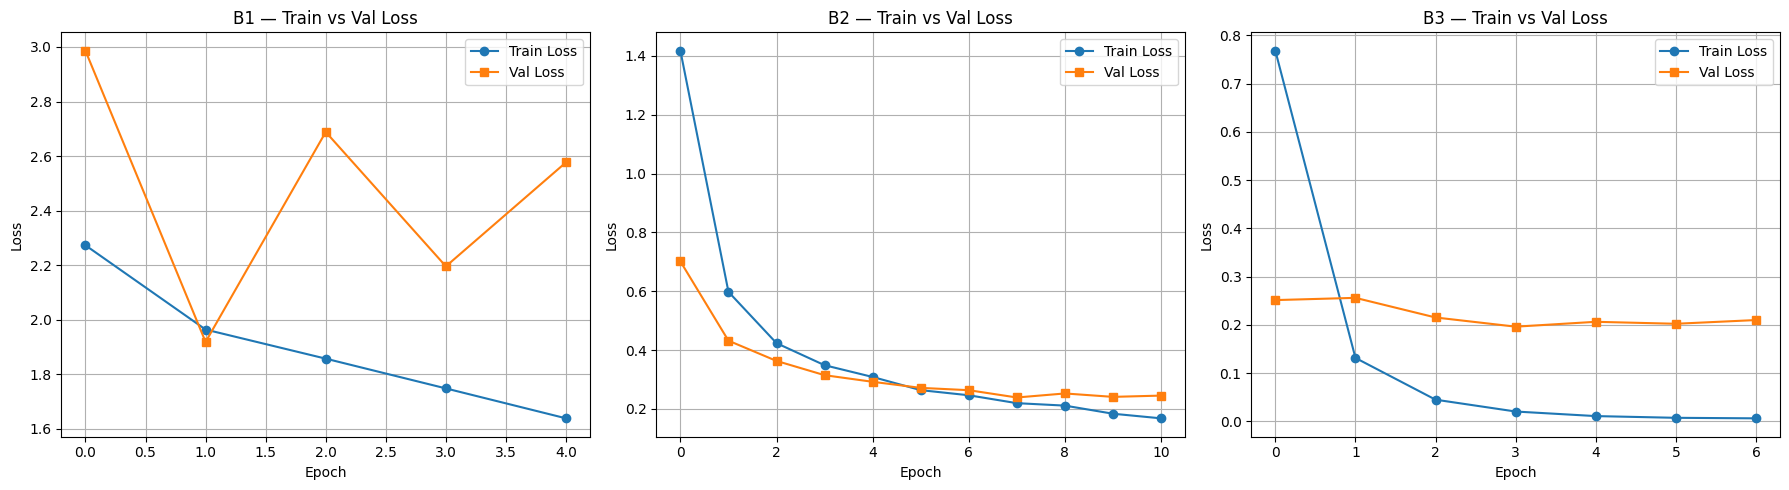

In [18]:
import pandas as pd

df = pd.read_csv('consolidated_results.csv')
print("\n=== Tabel Konsolidasi ===")
print(df.to_string(index=False))

# Grafik training vs validation loss untuk B1, B2, B3
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, cond in zip(axes, ['B1', 'B2', 'B3']):
    h = results[cond]['history']
    ax.plot(h['train_loss'], label='Train Loss', marker='o')
    ax.plot(h['val_loss'],   label='Val Loss',   marker='s')
    ax.set_title(f'{cond} — Train vs Val Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.savefig('curves_B1_B2_B3.png', dpi=150)
plt.show()

In [19]:
best_cond = 'B4'  # ganti sesuai model terbaik
model = models_dict[best_cond]
model.eval()

# Definisikan nama 10 kelas pertama Oxford-IIIT Pet (5 kucing pertama + 5 anjing pertama secara alfabetis)
# Kelas 0-9 di dataset Oxford-IIIT Pet:
selected_names = [
    "Abyssinian", "American Shorthair", "Birman", "Bengal", "British Shorthair",
    "Basset Hound", "Beagle", "Boxer", "Chihuahua", "English Cocker Spaniel"
]

raw_test = RemapDataset(combined, test_idx, label_map, transform=None)
misclassified = []

with torch.no_grad():
    for i in range(len(raw_test)):
        img_pil, label = raw_test[i]
        img_tensor = eval_transforms(img_pil).unsqueeze(0).to(device)
        out = model(img_tensor)
        prob = torch.softmax(out, dim=1)
        pred = out.argmax(1).item()
        conf = prob[0, pred].item()
        if pred != label:
            misclassified.append({
                'image': img_pil,
                'true': label,
                'pred': pred,
                'confidence': conf,
            })



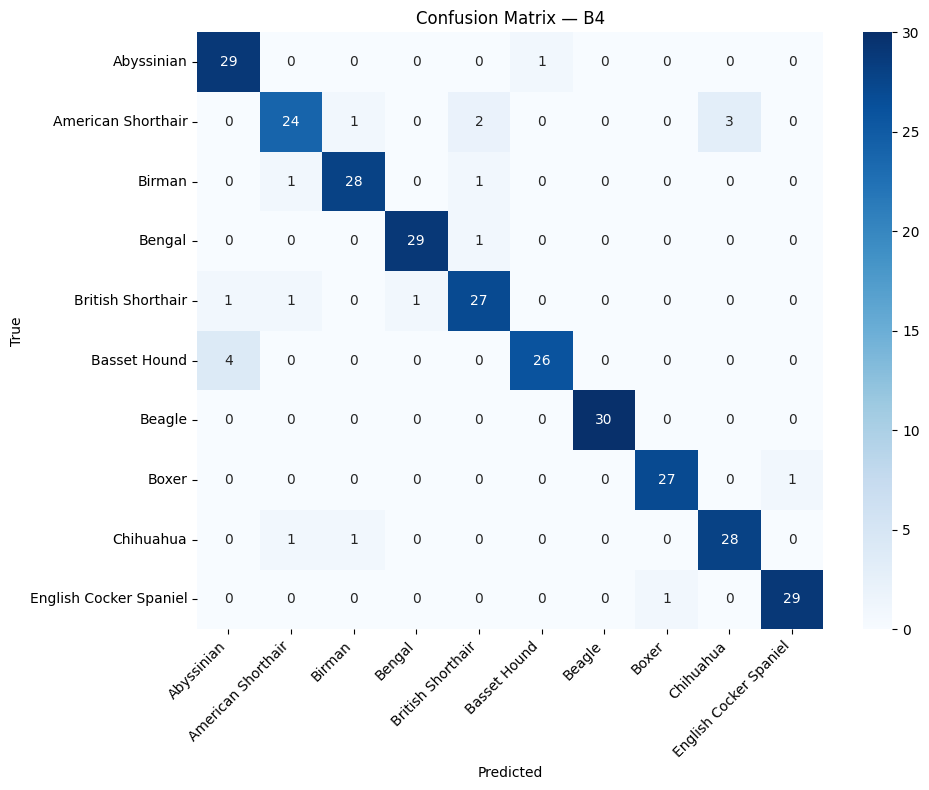

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

labels_all, preds_all, _ = test_outputs[best_cond]
cm = confusion_matrix(labels_all, preds_all)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=selected_names, yticklabels=selected_names)
plt.title(f'Confusion Matrix — {best_cond}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

In [21]:
import os
from google.colab import files
import shutil

os.makedirs('output_tugas05', exist_ok=True)
for f in ['log_B1.json','log_B2.json','log_B3.json','log_B4.json','log_B5.json',
          'consolidated_results.csv','curves_B1_B2_B3.png',
          'failure_analysis.png','confusion_matrix.png','gradcam_example.png']:
    if os.path.exists(f):
        shutil.copy(f, 'output_tugas05/')

shutil.make_archive('output_tugas05', 'zip', 'output_tugas05')
files.download('output_tugas05.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Menyimpan 8 dari 21 misklasifikasi...
  ✅ failure_cases/case1_true-British_Shorthair_pred-American_Shorthair.png (conf=0.563)
  ✅ failure_cases/case2_true-Basset_Hound_pred-Abyssinian.png (conf=0.623)
  ✅ failure_cases/case3_true-English_Cocker_Spaniel_pred-Boxer.png (conf=0.781)
  ✅ failure_cases/case4_true-Basset_Hound_pred-Abyssinian.png (conf=0.655)
  ✅ failure_cases/case5_true-British_Shorthair_pred-Abyssinian.png (conf=0.864)
  ✅ failure_cases/case6_true-American_Shorthair_pred-Birman.png (conf=0.626)
  ✅ failure_cases/case7_true-Bengal_pred-British_Shorthair.png (conf=0.561)
  ✅ failure_cases/case8_true-American_Shorthair_pred-British_Shorthair.png (conf=0.461)


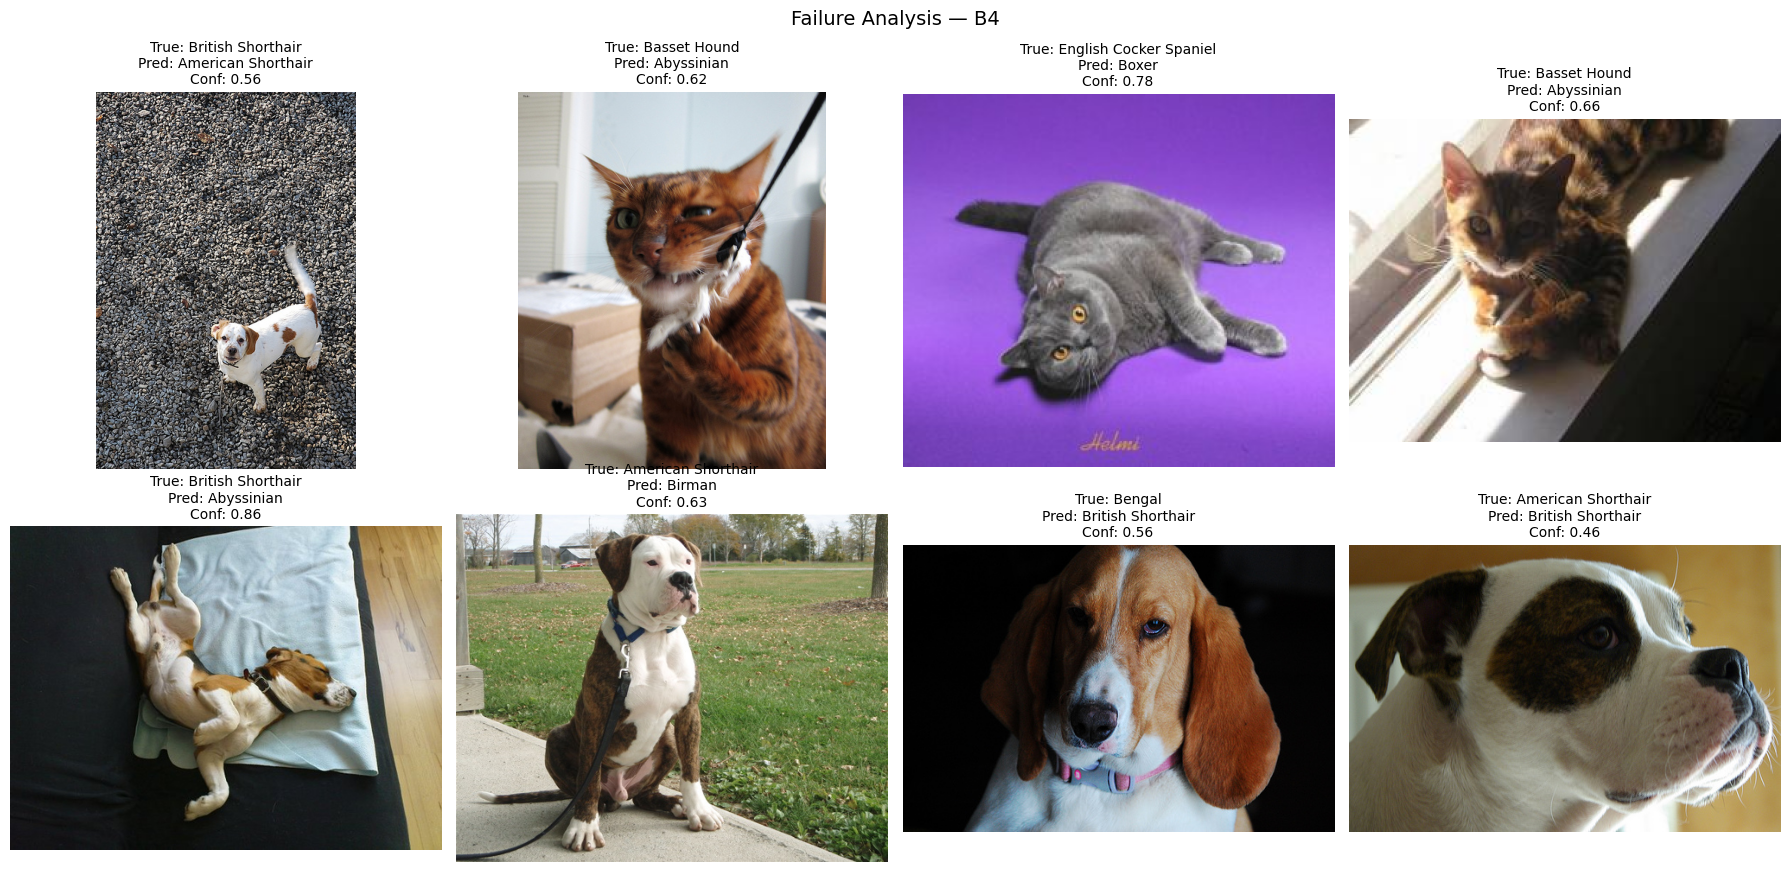


✅ 8 gambar disimpan di failure_cases/
✅ Grid disimpan sebagai failure_analysis.png

Isi folder failure_cases sekarang:
 - case1_true-British_Shorthair_pred-American_Shorthair.png
 - case2_true-Basset_Hound_pred-Abyssinian.png
 - case3_true-English_Cocker_Spaniel_pred-Boxer.png
 - case4_true-Basset_Hound_pred-Abyssinian.png
 - case5_true-British_Shorthair_pred-Abyssinian.png
 - case6_true-American_Shorthair_pred-Birman.png
 - case7_true-Bengal_pred-British_Shorthair.png
 - case8_true-American_Shorthair_pred-British_Shorthair.png


In [22]:
import os
import matplotlib.pyplot as plt

os.makedirs('failure_cases', exist_ok=True)

N_SHOW = min(8, len(misclassified))
print(f"Menyimpan {N_SHOW} dari {len(misclassified)} misklasifikasi...")

saved = []
for k, item in enumerate(misclassified[:N_SHOW]):
    true_name = selected_names[item['true']].replace(' ', '_')
    pred_name = selected_names[item['pred']].replace(' ', '_')
    fname = f"failure_cases/case{k+1}_true-{true_name}_pred-{pred_name}.png"
    item['image'].save(fname)
    saved.append(fname)
    print(f"  ✅ {fname} (conf={item['confidence']:.3f})")

# Grid
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for ax, item in zip(axes, misclassified[:N_SHOW]):
    ax.imshow(item['image'])
    ax.set_title(f"True: {selected_names[item['true']]}\n"
                 f"Pred: {selected_names[item['pred']]}\n"
                 f"Conf: {item['confidence']:.2f}", fontsize=10)
    ax.axis('off')
for ax in axes[N_SHOW:]:
    ax.axis('off')

plt.suptitle(f"Failure Analysis — {best_cond}", fontsize=14)
plt.tight_layout()
plt.savefig('failure_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ {len(saved)} gambar disimpan di failure_cases/")
print("✅ Grid disimpan sebagai failure_analysis.png")

# Cek ulang
print("\nIsi folder failure_cases sekarang:")
for f in sorted(os.listdir('failure_cases')):
    print(" -", f)

In [23]:
from google.colab import files
import shutil

shutil.make_archive('failure_cases', 'zip', 'failure_cases')
files.download('failure_cases.zip')
files.download('failure_analysis.png')

print("✅ Cek folder Downloads di komputer Anda")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Cek folder Downloads di komputer Anda
